# Лабораторная работа 3. Методы классификации

Датасет `powerconsumption.csv`: 52 416 наблюдений потребления энергии за 10-минутный интервал, тот же, что в работе 2.

- Datetime: интервал в десять минут
- Temperature: температура воздуха
- Humidity: влажность
- WindSpeed: скорость ветра
- GeneralDiffuseFlows, DiffuseFlows: рассеянная солнечная радиация
- PowerConsumption_Zone1/2/3: потребление по трём зонам города

Работаем с зоной 1. Прогнозируем потребление множественной регрессией, сводим прогноз к бинарной классификации «рост или спад» и сравниваем с моделями классификации.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.4})

In [2]:
df = pd.read_csv("powerconsumption.csv")
df['Datetime'] = pd.to_datetime(df['Datetime'], format = '%m/%d/%Y %H:%M')
df = df.set_index('Datetime').sort_index()

df_hour = df.resample('h').mean()
data = df_hour[['PowerConsumption_Zone1', 'Temperature', 'Humidity']].iloc[:3000]
print (data.shape)
data.head()

(3000, 3)


,PowerConsumption_Zone1,Temperature,Humidity
Datetime,,,
2017-01-01 00:00:00,29197.974683,6.196833,75.066667
2017-01-01 01:00:00,24657.215190,5.548833,77.583333
2017-01-01 02:00:00,22083.037973,5.054333,78.933333
2017-01-01 03:00:00,20811.139240,5.004333,77.083333
2017-01-01 04:00:00,20475.949367,5.097667,74.050000


## 1. Множественная регрессионная модель

Как и в работе 2, усредняем десятиминутные значения до часа. Берём первые 3000 часов, это 125 суток.

Предикторы - 24 предыдущих значения ряда, температура и влажность. Отклик - потребление в текущий час. Прогноз на один шаг вперёд, без рекурсии.

In [3]:
lags = 24
y = data['PowerConsumption_Zone1']

X = pd.concat([y.shift(i).rename(f'lag{i}') for i in range(1, lags + 1)]
              + [data['Temperature'], data['Humidity']], axis = 1).dropna()
y = y.loc[X.index]

train_len = int(len(X) * 0.8)
X_train, X_test = X.iloc[:train_len], X.iloc[train_len:]
y_train, y_test = y.iloc[:train_len], y.iloc[train_len:]
print (X_train.shape, X_test.shape)

(2380, 26) (596, 26)


Методы те же, что в работе 2: МНК через псевдообратную матрицу и SVR с RBF-ядром на стандартизованных признаках.

In [4]:
def mnk_fit(X, y):
    A = np.column_stack([np.ones(len(X)), X])
    return np.linalg.pinv(A) @ y

def mnk_pred(c, X):
    return pd.Series(c[0] + np.asarray(X) @ c[1:], index = X.index)

c = mnk_fit(X_train, y_train)
pred_mnk = mnk_pred(c, X_test)

In [5]:
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

svr = make_pipeline(StandardScaler(), SVR(C = 100)).fit(X_train, y_train)
pred_svr = pd.Series(svr.predict(X_test), index = X_test.index)

## 2. Адекватность моделей

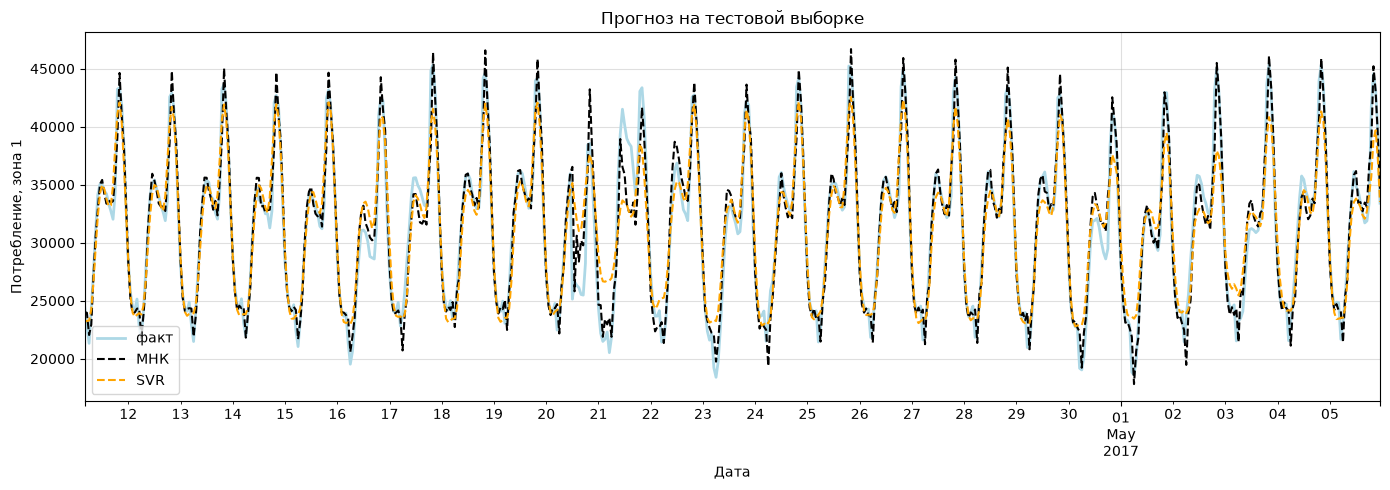

In [6]:
fig, ax = plt.subplots(figsize = (14, 5))

y_test.plot(ax = ax, label = 'факт', color = 'lightblue', linewidth = 2)
pred_mnk.plot(ax = ax, label = 'МНК', color = 'black', linestyle = '--')
pred_svr.plot(ax = ax, label = 'SVR', color = 'orange', linestyle = '--')

ax.set_xlabel('Дата')
ax.set_ylabel('Потребление, зона 1')
ax.set_title('Прогноз на тестовой выборке')
ax.legend()
plt.tight_layout()
plt.show()

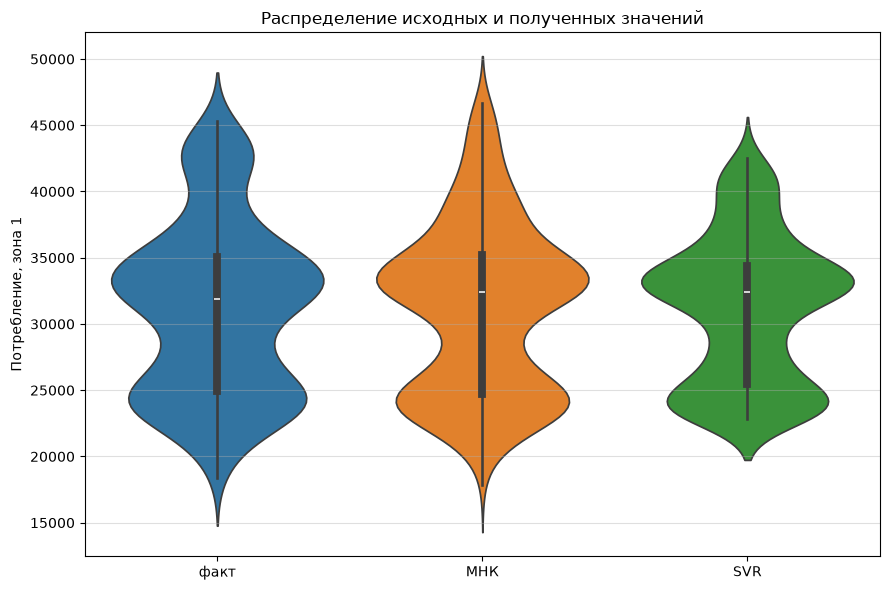

In [7]:
cmp = pd.DataFrame({'факт': y_test, 'МНК': pred_mnk, 'SVR': pred_svr})

fig, ax = plt.subplots(figsize = (9, 6))
sns.violinplot(data = cmp, ax = ax)
ax.set_ylabel('Потребление, зона 1')
ax.set_title('Распределение исходных и полученных значений')
plt.tight_layout()
plt.show()

In [8]:
def metrics(real, pred):
    real, pred = np.asarray(real), np.asarray(pred)
    mae = np.mean(np.abs(real - pred))
    rmse = np.sqrt(np.mean((real - pred) ** 2))
    mape = np.mean(np.abs(real - pred) / real) * 100
    mase = mae / np.mean(np.abs(np.diff(y_train.values)))
    return [mae, rmse, mape, mase]

reg_metrics = pd.DataFrame({'МНК': metrics(y_test, pred_mnk), 'SVR': metrics(y_test, pred_svr)},
                           index = ['MAE', 'RMSE', 'MAPE', 'MASE']).T.round(3)
reg_metrics

,MAE,RMSE,MAPE,MASE
МНК,1142.347,1654.618,3.724,0.537
SVR,1552.790,2128.164,5.146,0.731


Лучшая модель - МНК: MAE 1142 против 1553 у SVR, MAPE 3.7% против 5.1%. MASE меньше единицы у обеих моделей (0.54 и 0.73), то есть обе точнее наивного прогноза «как в предыдущий час».

На скрипичных диаграммах у МНК обе моды на своих местах и размах близок к фактическому (17.8-46.7 тысяч против 18.4-45.4). SVR стягивает прогноз к середине: размах 22.8-42.6 тысяч, стандартное отклонение 5482 против 6502 у факта. Эпсилон-полоса гасит редкие ночные провалы и вечерние пики. Дальше в классификацию переводим прогноз МНК.

## 3. Переход к задаче классификации

Класс 1 - потребление растёт по сравнению с предыдущим часом, класс 0 - падает.

In [9]:
prev = data['PowerConsumption_Zone1'].shift(1).loc[X.index]

cls = (y > prev).astype(int)
cls_train, cls_test = cls.iloc[:train_len], cls.iloc[train_len:]

print (cls.value_counts())
print (round(cls_train.mean(), 3), round(cls_test.mean(), 3))

PowerConsumption_Zone1
0    1644
1    1332
Name: count, dtype: int64
0.443 0.465


Классы почти сбалансированы: 44.3% единиц на обучении и 46.5% на тесте. Перевес нулей объясняется формой суточного цикла: спад после вечернего пика длиннее, чем утренний подъём.

## 4. Классификация методами kNN и SVM

Признаки те же, что у регрессии. Число соседей подбираем кросс-проверкой с разбиением по времени.

In [10]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

score = {k: cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(k)),
                            X_train, cls_train, cv = TimeSeriesSplit(5), scoring = 'accuracy').mean()
         for k in range(1, 21, 2)}
k_best = max(score, key = score.get)
print (k_best, round(score[k_best], 3))

9 0.872


In [11]:
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(k_best)).fit(X_train, cls_train)
svm = make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(), ensemble = False)).fit(X_train, cls_train)

## 5. Дополнительные методы: логистическая регрессия и LDA

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter = 1000)).fit(X_train, cls_train)
lda = LinearDiscriminantAnalysis().fit(X_train, cls_train)

## 6. Сравнение качества

Прогноз МНК переводим в классы тем же правилом: 1, если предсказанное значение выше фактического значения предыдущего часа.

In [13]:
from sklearn.metrics import (accuracy_score, f1_score, log_loss, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay)

prev_test = prev.iloc[train_len:]
reg_cls = (pred_mnk > prev_test).astype(int)

proba = {'kNN': knn.predict_proba(X_test)[:, 1],
         'SVM': svm.predict_proba(X_test)[:, 1],
         'LogReg': logreg.predict_proba(X_test)[:, 1],
         'LDA': lda.predict_proba(X_test)[:, 1]}

rows = {name: [accuracy_score(cls_test, p > 0.5), f1_score(cls_test, p > 0.5),
               log_loss(cls_test, p), roc_auc_score(cls_test, p)]
        for name, p in proba.items()}
rows['МНК -> классы'] = [accuracy_score(cls_test, reg_cls), f1_score(cls_test, reg_cls), np.nan, np.nan]

cls_metrics = pd.DataFrame(rows, index = ['Accuracy', 'F1', 'LogLoss', 'ROC-AUC']).T.round(3)
cls_metrics

,Accuracy,F1,LogLoss,ROC-AUC
kNN,0.854,0.835,1.095,0.925
SVM,0.849,0.828,0.320,0.946
LogReg,0.857,0.832,0.300,0.949
LDA,0.872,0.854,0.332,0.936
МНК -> классы,0.841,0.834,NaN,NaN


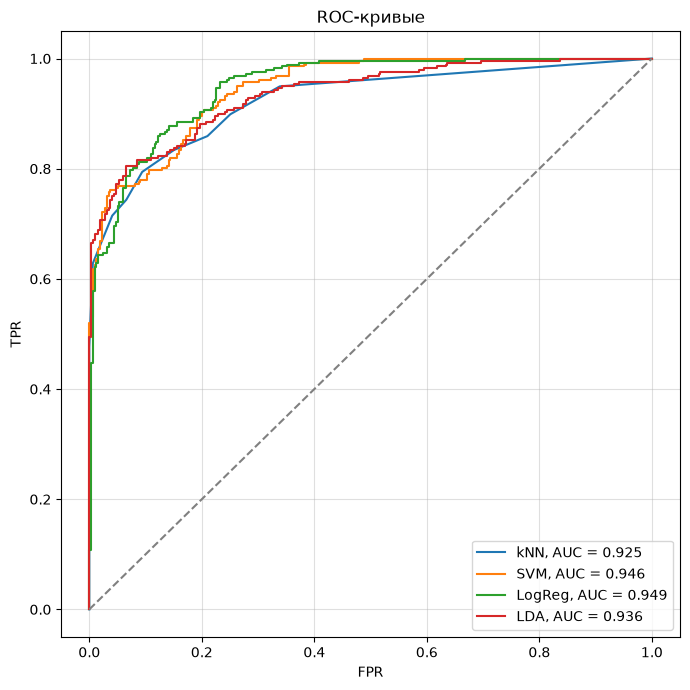

In [14]:
fig, ax = plt.subplots(figsize = (7, 7))

for name, p in proba.items():
    fpr, tpr, _ = roc_curve(cls_test, p)
    ax.plot(fpr, tpr, label = f'{name}, AUC = {roc_auc_score(cls_test, p):.3f}')

ax.plot([0, 1], [0, 1], color = 'gray', linestyle = '--')
ax.set_xlabel('FPR')
ax.set_ylabel('TPR')
ax.set_title('ROC-кривые')
ax.legend()
plt.tight_layout()
plt.show()

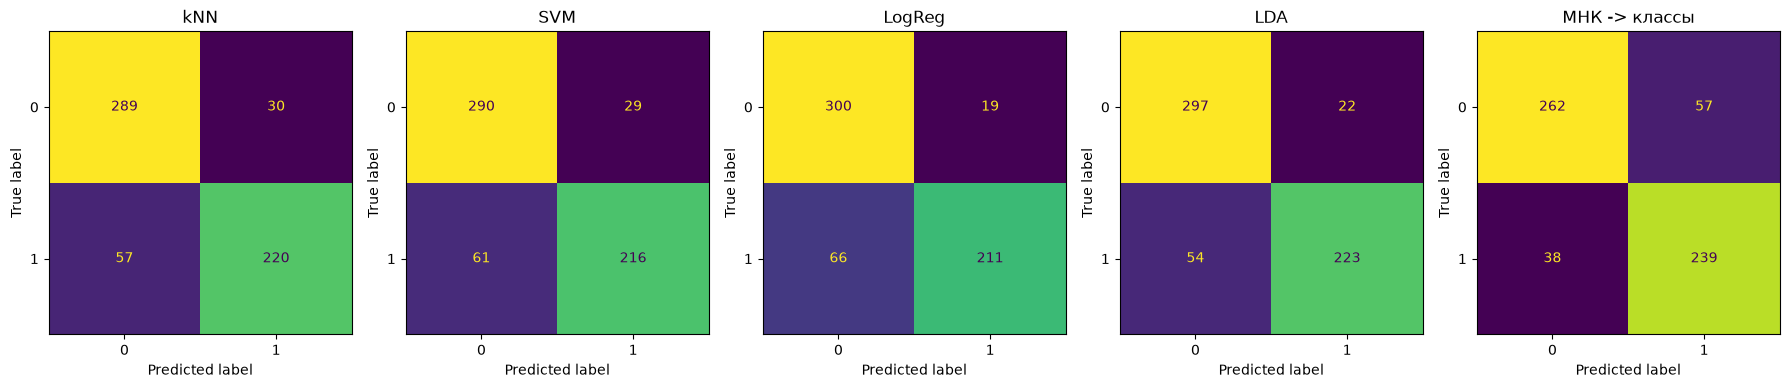

In [15]:
preds = {name: (p > 0.5).astype(int) for name, p in proba.items()}
preds['МНК -> классы'] = reg_cls

fig, axes = plt.subplots(1, 5, figsize = (18, 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(cls_test, p)).plot(ax = ax, colorbar = False)
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

#### Выводы

Точность всех пяти моделей лежит в узкой полосе 0.84-0.87. Лучшая по Accuracy и F-мере - LDA (0.872 и 0.854), лучшая по LogLoss и ROC-AUC - логистическая регрессия (0.300 и 0.949). Линейные методы выигрывают, потому что разделяющая поверхность здесь близка к линейной: знак приращения определяется в основном разностью последних лагов.

kNN с k = 9 даёт сопоставимую точность 0.854, но LogLoss 1.095, втрое хуже остальных. Вероятность у kNN - доля соседей одного класса, она принимает десять значений и часто равна 0 или 1, а уверенная ошибка штрафуется логарифмом тяжело. По ROC-AUC (0.925) метод при этом не хуже SVM.

Регрессия, сведённая к классам, отстаёт незначительно: Accuracy 0.841 против 0.872 у LDA. Модель обучалась восстанавливать само значение, а не знак приращения, и теряет точность там, где приращение близко к нулю. LogLoss и ROC-AUC для неё не считаются: правило «прогноз выше предыдущего часа» даёт готовую метку, а не вероятность.

У четырёх классификаторов ошибки смещены в сторону нуля: у SVM 61 пропуск роста против 29 ложных срабатываний, у LogReg 66 против 19. Нулей в обучающей выборке больше, и модели чаще отвечают «спад». Регрессия ошибается наоборот: 57 ложных срабатываний против 38 пропусков. Она сглаживает резкие спады, прогноз остаётся выше предыдущего часа, и правило даёт лишнюю единицу.

## 7. Несбалансированные классы

Меняем принцип разбиения: класс 1 присваиваем только заметному росту, больше 10% к предыдущему часу. Слабые колебания уходят в класс 0.

In [16]:
cls2 = (y > prev * 1.10).astype(int)
cls2_train, cls2_test = cls2.iloc[:train_len], cls2.iloc[train_len:]

print (cls2.value_counts())
print (round(cls2_train.mean(), 3), round(cls2_test.mean(), 3))

PowerConsumption_Zone1
0    2506
1     470
Name: count, dtype: int64
0.161 0.148


In [17]:
models = {'kNN': make_pipeline(StandardScaler(), KNeighborsClassifier(k_best)),
          'SVM': make_pipeline(StandardScaler(), CalibratedClassifierCV(SVC(), ensemble = False)),
          'LogReg': make_pipeline(StandardScaler(), LogisticRegression(max_iter = 1000)),
          'LDA': LinearDiscriminantAnalysis()}

rows2 = {}
for name, m in models.items():
    m.fit(X_train, cls2_train)
    p = m.predict_proba(X_test)[:, 1]
    rows2[name] = [accuracy_score(cls2_test, p > 0.5), f1_score(cls2_test, p > 0.5),
                   log_loss(cls2_test, p), roc_auc_score(cls2_test, p)]

cls2_metrics = pd.DataFrame(rows2, index = ['Accuracy', 'F1', 'LogLoss', 'ROC-AUC']).T.round(3)
cls2_metrics

,Accuracy,F1,LogLoss,ROC-AUC
kNN,0.908,0.712,0.827,0.908
SVM,0.911,0.710,0.215,0.944
LogReg,0.914,0.736,0.184,0.960
LDA,0.888,0.691,0.266,0.950


In [18]:
pd.DataFrame({'Accuracy сбаланс.': cls_metrics.loc[list(models), 'Accuracy'],
              'Accuracy несбаланс.': cls2_metrics['Accuracy'],
              'F1 сбаланс.': cls_metrics.loc[list(models), 'F1'],
              'F1 несбаланс.': cls2_metrics['F1']})

,Accuracy сбаланс.,Accuracy несбаланс.,F1 сбаланс.,F1 несбаланс.
kNN,0.854,0.908,0.835,0.712
SVM,0.849,0.911,0.828,0.710
LogReg,0.857,0.914,0.832,0.736
LDA,0.872,0.888,0.854,0.691


#### Выводы

Новая граница даёт долю единиц 0.161 на обучении и 0.148 на тесте, классы разошлись примерно один к шести.

Accuracy выросла у всех моделей (у LogReg с 0.857 до 0.914), но сравнивать её с предыдущим результатом нельзя: поднялся и базовый уровень. Модель, которая всегда отвечает нулём, здесь набирает 0.852 против 0.535 в сбалансированной задаче, то есть по отношению к базовому уровню качество упало.

Реальную картину показывает F-мера, и она просела у всех: у LDA с 0.854 до 0.691, у kNN с 0.835 до 0.712. Редкий класс распознаётся хуже, примеров для него в обучающей выборке в шесть раз меньше.

LogLoss и ROC-AUC при этом улучшились (у LogReg 0.300 -> 0.184 и 0.949 -> 0.960). Скачки больше 10% приходятся на утренний и вечерний подъёмы, они предсказуемы по лагам и отделяются от остальных часов увереннее, чем слабые колебания около нуля. Проигрыш идёт именно на пороге 0.5: модель осторожничает с редким классом и теряет полноту.

По LogLoss и ROC-AUC логистическая регрессия остаётся лучшей в обеих постановках, а по F-мере она выходит вперёд только на несбалансированных классах: 0.736 против 0.691 у LDA.